SENTIMENT ANALYSIS

1. INSTALL LIBRARIES IF REQUIRED

In [ ]:
!pip install -q "kagglehub[pandas-datasets]" wordcloud

2. IMPORTS

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

3. LOAD DATASET FROM KAGGLE

In [ ]:
file_path = "Dataset-SA.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "niraliivaghani/flipkart-product-customer-reviews-dataset",
    file_path
)

print("First 5 records:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Check expected columns
print("\nAvailable columns after standardization:")
print(df.columns.tolist())

# This dataset contains Review, Summary and Sentiment columns.
# Use Review as the text input and Sentiment as the target.
required_columns = ["review", "sentiment"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )


/tmp/ipykernel_3575/995897257.py:3: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'flipkart-product-customer-reviews-dataset' dataset.
First 5 records:
                                        product_name product_price Rate  \
0  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    5   
1  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    5   
2  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    3   
3  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    1   
4  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    3   

            Review                                            Summary  \
0           super!  great cooler excellent air flow and for this p...   
1          awesome              best budget 2 fit cooler nice cooling   
2             fair  the quality is good but the power of air is de...   
3  useless product                  very bad product its a only a fan   
4             fair                                      ok ok product  

4. DATA CLEANING

In [ ]:
df = df.dropna(subset=["review", "sentiment"]).copy()

df["review"] = df["review"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

df = df[
    (df["review"] != "") &
    (df["sentiment"] != "")
].copy()

# Retain only the three expected sentiment classes
df = df[
    df["sentiment"].isin(["positive", "negative", "neutral"])
].copy()

df = df.drop_duplicates(subset=["review", "sentiment"]).reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)


Cleaned dataset shape: (1469, 6)


5. INSPECTING SENTIMENT CLASS DISTRIBUTION


Sentiment counts:
sentiment
positive    1044
negative     316
neutral      109
Name: count, dtype: int64

Sentiment percentages:
sentiment
positive    71.07
negative    21.51
neutral      7.42
Name: proportion, dtype: float64


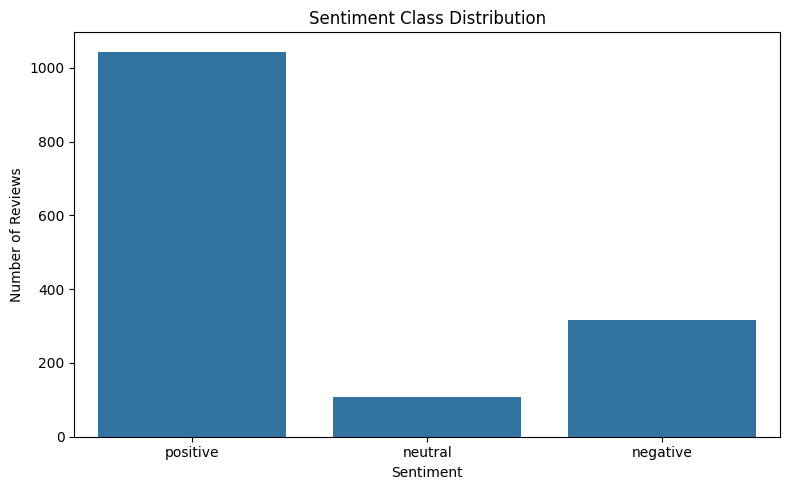

In [ ]:
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    (df["sentiment"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="sentiment",
    order=["positive", "neutral", "negative"]
)
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

6. TEXT PROCESSING

In [ ]:
stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization
    tokens = text.split()

    # Stopword removal
    tokens = [word for word in tokens if word not in stop_words]

    # Optional stemming using a simple suffix-based approach
    # is intentionally omitted to avoid damaging words.
    return " ".join(tokens)

df["cleaned_review"] = df["review"].apply(preprocess_text)

# Remove reviews that become empty after preprocessing
df = df[df["cleaned_review"].str.strip() != ""].copy()

print("\nOriginal review:")
print(df["review"].iloc[0])

print("\nPreprocessed review:")
print(df["cleaned_review"].iloc[0])


Original review:
super!

Preprocessed review:
super


7. DEFINING INPUTS & OUTPUTS AND MAKING A TRAIN-TEST SPLIT

In [ ]:
X = df["cleaned_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 1168
Testing samples: 292

Training class distribution:
sentiment
positive    828
negative    253
neutral      87
Name: count, dtype: int64

Testing class distribution:
sentiment
positive    207
negative     63
neutral      22
Name: count, dtype: int64


8. DEFINING TWO CLASSIFICATION MODELS

In [ ]:
models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", MultinomialNB())
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

9. TRAINING AND EVALUATING BOTH THE MODELS


Naive Bayes
Accuracy: 0.7500
Macro Precision: 0.4789
Macro Recall: 0.4152
Macro F1-score: 0.4129
Weighted F1-score: 0.6876

Classification Report:
              precision    recall  f1-score   support

    negative       0.68      0.27      0.39        63
     neutral       0.00      0.00      0.00        22
    positive       0.76      0.98      0.85       207

    accuracy                           0.75       292
   macro avg       0.48      0.42      0.41       292
weighted avg       0.68      0.75      0.69       292



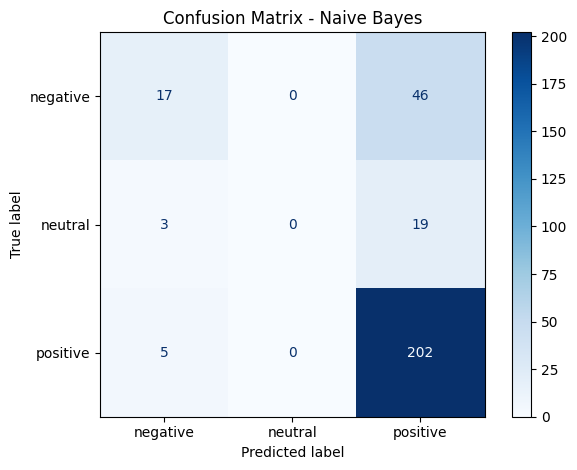


Logistic Regression
Accuracy: 0.6027
Macro Precision: 0.4515
Macro Recall: 0.4629
Macro F1-score: 0.4395
Weighted F1-score: 0.6375

Classification Report:
              precision    recall  f1-score   support

    negative       0.40      0.37      0.38        63
     neutral       0.12      0.32      0.17        22
    positive       0.83      0.71      0.76       207

    accuracy                           0.60       292
   macro avg       0.45      0.46      0.44       292
weighted avg       0.69      0.60      0.64       292



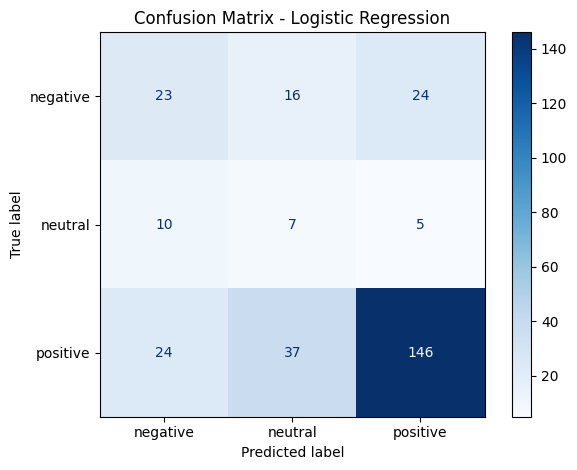

In [ ]:
results = []
predictions = {}

class_labels = ["negative", "neutral", "positive"]

for name, model in models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # Train model
    model.fit(X_train, y_train)

    # Predict test labels
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Weighted F1": weighted_f1
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall: {recall:.4f}")
    print(f"Macro F1-score: {f1:.4f}")
    print(f"Weighted F1-score: {weighted_f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

10. WORD CLOUD FOR EACH SENTIMENT CLASS

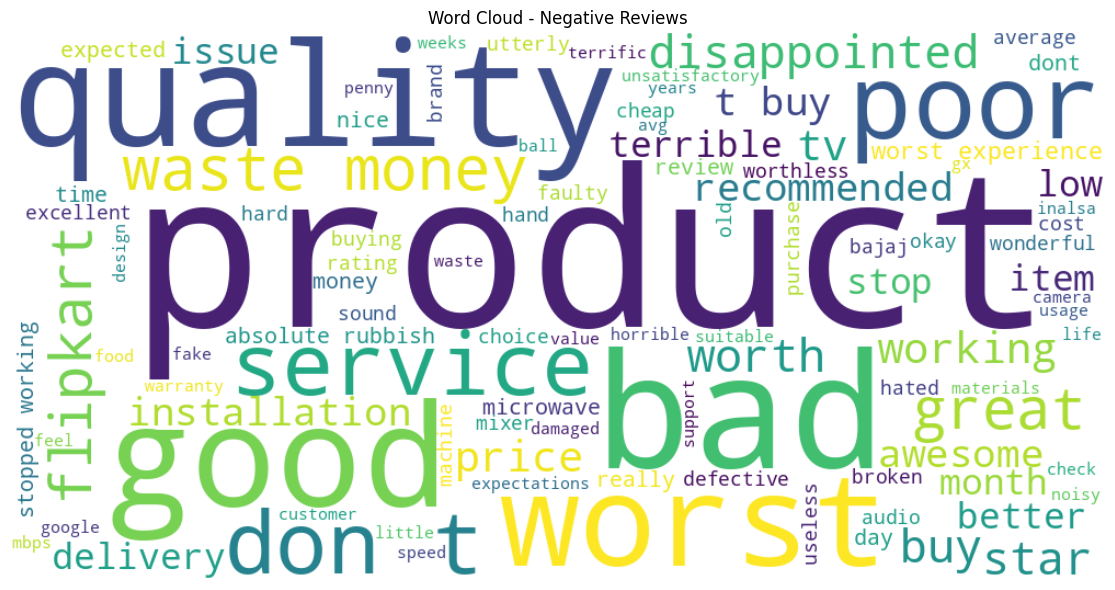

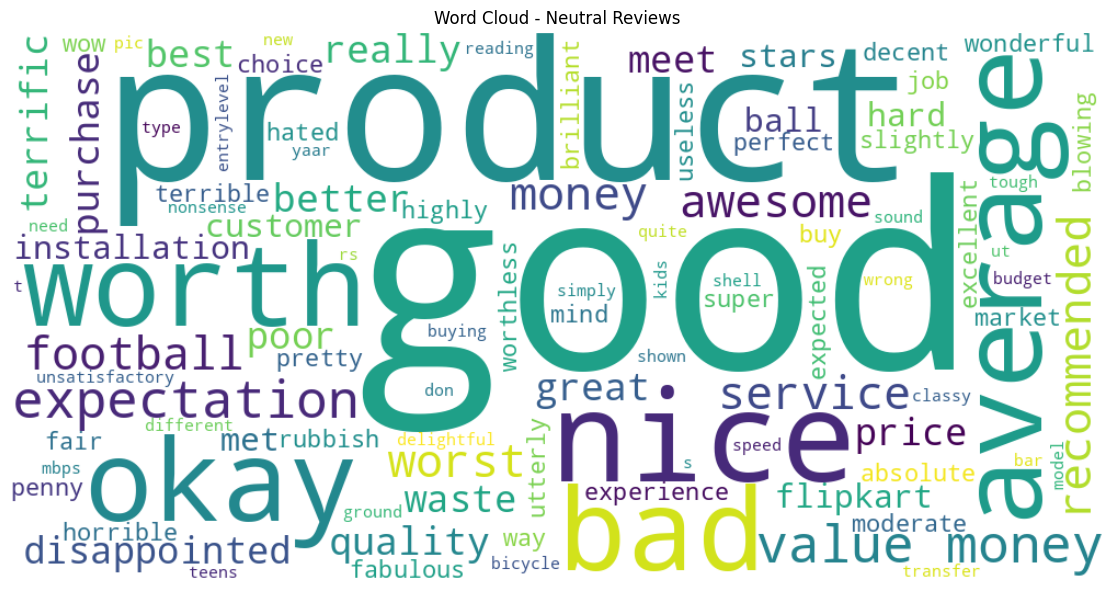

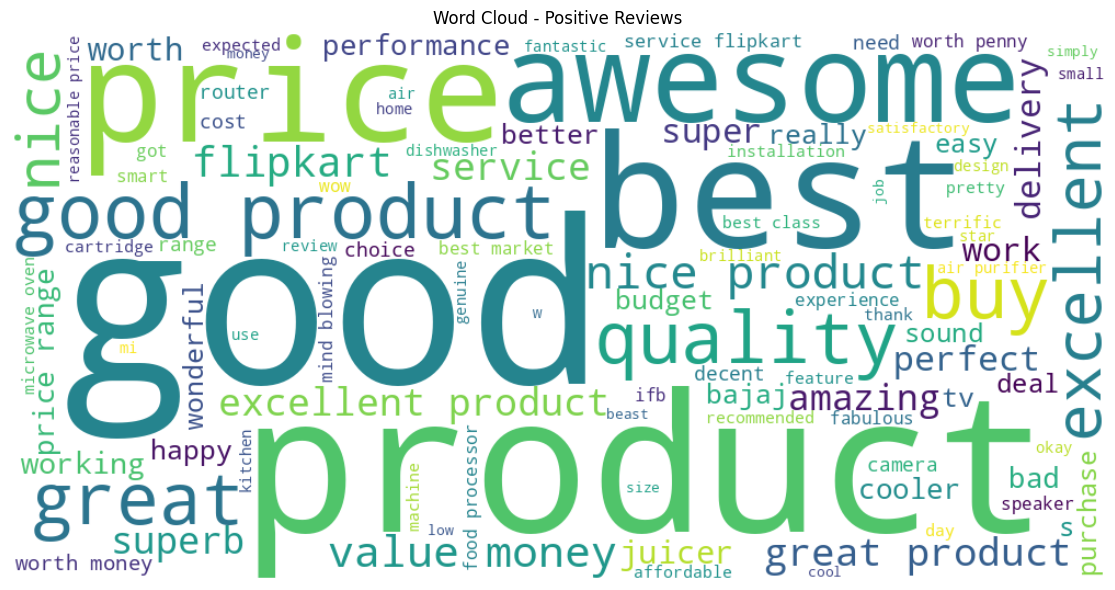

In [ ]:
for sentiment in class_labels:

    sentiment_text = " ".join(
        df.loc[
            df["sentiment"] == sentiment,
            "cleaned_review"
        ].astype(str)
    )

    if sentiment_text.strip():
        wordcloud = WordCloud(
            width=1000,
            height=500,
            background_color="white",
            max_words=100
        ).generate(sentiment_text)

        plt.figure(figsize=(12, 6))
        plt.imshow(wordcloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"Word Cloud - {sentiment.capitalize()} Reviews")
        plt.tight_layout()
        plt.show()


11. ERROR ANALYSIS

In [ ]:
error_data = pd.DataFrame({
    "Review": X_test,
    "Actual Sentiment": y_test
})

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(f"ERROR ANALYSIS - {name}")
    print("=" * 60)

    errors = error_data.copy()
    errors["Predicted Sentiment"] = y_pred

    errors = errors[
        errors["Actual Sentiment"] != errors["Predicted Sentiment"]
    ]

    if errors.empty:
        print("No misclassified examples on the test set.")
    else:
        print(f"Total misclassified reviews: {len(errors)}")
        print("\nFirst 5 misclassified examples:")
        print(
            errors[
                ["Review", "Actual Sentiment", "Predicted Sentiment"]
            ].head(5).to_string(index=False)
        )

        print(
            "\nPossible reasons: sarcasm, mixed opinions, "
            "short reviews, ambiguous wording, spelling errors, "
            "or sentiment labels that do not perfectly reflect "
            "the review text."
        )


ERROR ANALYSIS - Naive Bayes
Total misclassified reviews: 73

First 5 misclassified examples:
              Review Actual Sentiment Predicted Sentiment
    good hard ground          neutral            positive
            just wow         negative            positive
stopped working mins         positive            negative
       fake purifier         negative            positive
   review half years         negative            positive

Possible reasons: sarcasm, mixed opinions, short reviews, ambiguous wording, spelling errors, or sentiment labels that do not perfectly reflect the review text.

ERROR ANALYSIS - Logistic Regression
Total misclassified reviews: 116

First 5 misclassified examples:
              Review Actual Sentiment Predicted Sentiment
          good cycle         positive             neutral
            just wow         negative             neutral
stopped working mins         positive            negative
       fake purifier         negative            positive
 

12. MODEL COMPARISON


MODEL COMPARISON
                     Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
Model                                                                              
Naive Bayes            0.7500           0.4789        0.4152    0.4129       0.6876
Logistic Regression    0.6027           0.4515        0.4629    0.4395       0.6375


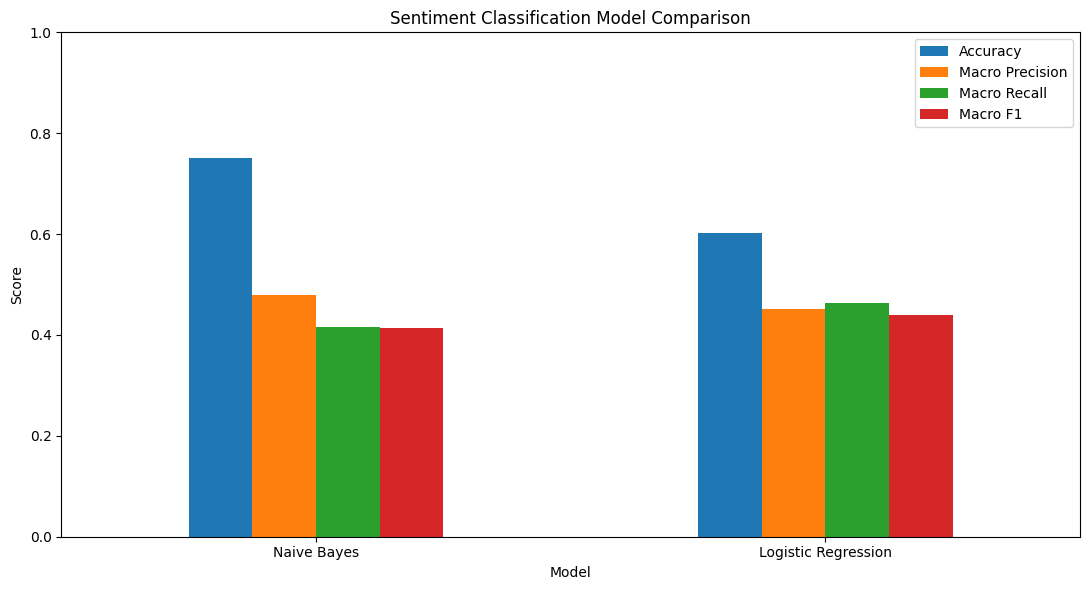

In [ ]:
comparison = pd.DataFrame(results).set_index("Model")

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(comparison.round(4).to_string())

comparison[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


13. SELECTING BEST MODEL BASED ON MACRO F1

In [ ]:
best_model_name = comparison["Macro F1"].idxmax()
best_model = models[best_model_name]

print("\nBest model based on Macro F1:", best_model_name)
print("Macro F1-score:", round(
    comparison.loc[best_model_name, "Macro F1"], 4
))

print("\nCONCLUSION")
print(
    f"{best_model_name} performed best on this test split "
    "according to macro F1-score. Macro F1 considers all three "
    "sentiment classes equally, which is useful when class "
    "distribution is imbalanced."
)

print(
    "\nReal-world applications include analyzing customer feedback, "
    "identifying product complaints, tracking customer satisfaction, "
    "and helping businesses understand public opinion."
)


Best model based on Macro F1: Logistic Regression
Macro F1-score: 0.4395

CONCLUSION
Logistic Regression performed best on this test split according to macro F1-score. Macro F1 considers all three sentiment classes equally, which is useful when class distribution is imbalanced.

Real-world applications include analyzing customer feedback, identifying product complaints, tracking customer satisfaction, and helping businesses understand public opinion.


14. TESTING THE MODEL ON A NEW REVIEW

In [ ]:
new_review = ["The product is excellent and works perfectly"]

cleaned_new_review = [preprocess_text(new_review[0])]

predicted_sentiment = best_model.predict(cleaned_new_review)[0]

print("\nNew review:", new_review[0])
print("Predicted sentiment:", predicted_sentiment)



New review: The product is excellent and works perfectly
Predicted sentiment: positive
